<a href="https://colab.research.google.com/github/JoseCamachoS/Metodos-nunericos-l/blob/main/metodo_newton_raphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font color="cyan">**Método de Newton **</font>

  Queremos encontrar la raiz de una función con una aporximación $p_0$ usando la ecuación $p_n=p_{n-1}-f(p_{n-1})/f'(p_{n-1})$, con $n \ge 1$ .
  Y para hallar la raiz de f(x)=0 el valor de la función debe estár definida en cada iteración, es decir $f'(x)$ debe ser distinto de cero para cada $p_n$

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd # para crear  la tabla mas adelante
# se importan las librerias necesarias

Y queremos encontrar la raiz de $f(x)=cos(x)-x$
Calculando su derivada: $f´(x)=-sen(x)-1$
y por lo tanto la fórmula de iteración de Newton-Raphson es:
$$p_n = p_{n-1} - \frac{f(p_{n-1})}{f'(p_{n-1})} = p_{n-1} + \frac{\cos(p_{n-1}) - p_{n-1}}{\sin(p_{n-1}) + 1}$$

In [10]:
def f(x):
    return np.cos(x) - x
  # definimos la función

Graficando $f(x)=cos(x)-x$

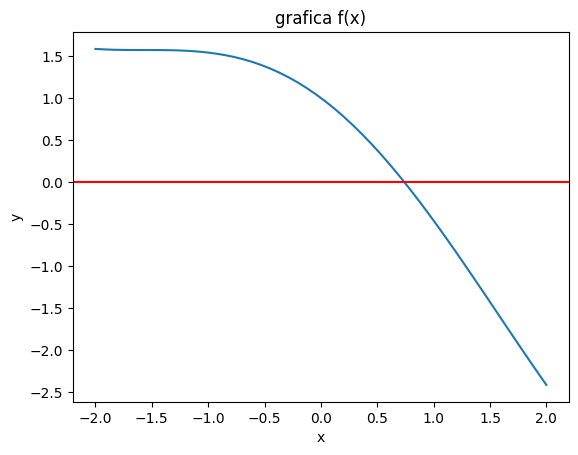

In [11]:
xx=np.linspace(-2,2) #genera una particion
plt.plot(xx,f(xx))#muestra las parejas ordendas, (x,y)
plt.title('grafica f(x)')#titulo superior de la gráfica
plt.xlabel('x')
plt.ylabel('y')

plt.axhline(y=0,color='red')#trazar linea horizontal en Y=0

Y la función iterativa queda de la siguiente forma

In [12]:
def g(x):
  return x+(np.cos(x)-x)/(np.sin(x)+1)

In [40]:
def newton(p0, tol, n_iter):#definimos la funcion con los parametros de p0=valor inicial para pn-1, tlerancia y numero maximo de iteraciones
    iteraciones = []
    error = []
    L_pi = []
    l_p1=[]
    #creamos listas para cada columna de la tabla
    for i in range(1, n_iter + 1):
        p = g(p0)# por def. del metodo, pn=g(pn-1)
        e = abs(p - p0) #calculamos el error

        iteraciones.append(i)
        L_pi.append(p0)
        error.append(e)
        l_p1.append(p) #agregamos el elemento a cada columna basandonos en los valores de la iteracion


        if e < tol:
            print(f"La raíz aproximada p es: {p}")# si el error es menor que la tolerancia se termina el ciclo e imprimimos la tabla
            df = pd.DataFrame({
                'Iteración (i)': iteraciones,
                'p_i': L_pi,
                'p_n-1': l_p1,
                'Error |p_i - p_{i-1}|': error
            })
            return  df

        p0 = p  # actualizamos el valor de p0

    #imprimimos que el metodo fallo si excedemos las iteraciones sin llegar a la raiz deseada
    print(f"El método falló después de {n_iter} iteraciones. El último valor de p_n fue: {p}")
    df = pd.DataFrame({
        'Iteración (i)': iteraciones,
        'p_n-1': L_pi,
        'p_n-1': l_p1,
        'Error |p_i - p_{i-1}|': error
    })
    return  df

In [41]:
resultado=newton(0.5,1e-8,10) # probamos el algoritmo con un valor p0=0.5, tolrancia de 10^-8 y un numero maximo de 10 iteraciones

La raíz aproximada p es: 0.7390851332151607


In [42]:
print(resultado) #imprimimos el dataframe

   Iteración (i)       p_i     p_n-1  Error |p_i - p_{i-1}|
0              1  0.500000  0.755222           2.552224e-01
1              2  0.755222  0.739142           1.608075e-02
2              3  0.739142  0.739085           5.653223e-05
3              4  0.739085  0.739085           7.056461e-10
